# Лабораторная работа №7. Классификация бронирований

**Цель:** по данным бронирования жилого помещения предсказать, будет ли заключена сделка купли-продажи. Сравниваются K ближайших соседей (KNN) и дерево решений. Выполнено дополнительное задание: подбор числа соседей и глубины дерева.

Источник данных — `База.csv` из комплекта задания. Положите CSV рядом с этим блокнотом перед запуском.

## 1. Загрузка и первичная фильтрация

В анализ входят только жилые помещения с определённым итогом бронирования. Значение «Продана» кодируется как 1, «Свободна» (бронь отменена) — как 0. Записи со статусом «В резерве» и без итогового статуса исключаются, поскольку для них целевая метка пока неизвестна. Идентификатор брони и вид помещения удаляются из факторов.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import f1_score, precision_score, recall_score, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
DATA_PATH = Path("База.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Не найден файл {DATA_PATH.resolve()}. Поместите База.csv рядом с блокнотом.")

df = pd.read_csv(DATA_PATH, sep=";", encoding="cp1251", decimal=",")
print(f"Исходный размер: {df.shape[0]:,} строк × {df.shape[1]} столбцов".replace(",", " "))
display(df.head(3))

Исходный размер: 5 519 строк × 21 столбцов
                              УИД_Брони  ... Статус лида (из CRM)
0  d192173f-fc14-11eb-9512-000c29ad50ac  ...                    S
1  43574a1f-fe8b-11eb-9512-000c29ad50ac  ...                    F
2  0e7b7a81-fe97-11eb-9512-000c29ad50ac  ...                    S

[3 rows x 21 columns]


## 2. Целевой признак и баланс классов

Оставляются жилые помещения со статусами «Продана» и «Свободна». Статусы «В резерве» и пропуски исключаются. Для модели 1 означает состоявшуюся продажу, 0 — отменённую бронь. Идентификатор брони, целевой статус и вид помещения не входят в факторы.

Жилых помещений: 4 105
Строк с известным итоговым статусом: 3 944
Исключено как резерв/неизвестный статус: 161

Баланс целевого признака:


,Количество,"Доля, %"
Бронь отменена (0),2804,71.1
Продана (1),1140,28.9


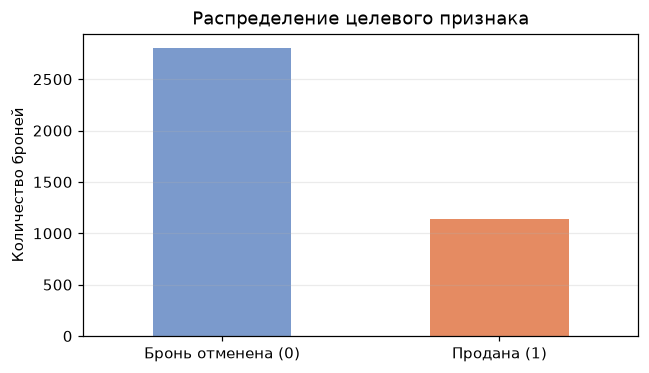

In [2]:
residential = df.loc[df["ВидПомещения"].eq("жилые помещения")].copy()
usable = residential.loc[residential["СледующийСтатус"].isin(["Продана", "Свободна"])].copy()
y = usable["СледующийСтатус"].map({"Свободна": 0, "Продана": 1}).astype("int8")
X = usable.drop(columns=["УИД_Брони", "СледующийСтатус", "ВидПомещения"]).copy()

print(f"Жилых помещений: {len(residential):,}".replace(",", " "))
print(f"Строк с известным итоговым статусом: {len(usable):,}".replace(",", " "))
print(f"Исключено как резерв/неизвестный статус: {len(residential) - len(usable):,}".replace(",", " "))
print()
print("Баланс целевого признака:")
summary = pd.DataFrame({"Количество": y.value_counts().sort_index(), "Доля, %": (100 * y.value_counts(normalize=True).sort_index()).round(2)})
summary.index = ["Бронь отменена (0)", "Продана (1)"]
display(summary)

fig, ax = plt.subplots(figsize=(6, 3.5))
summary["Количество"].plot(kind="bar", color=["#7b9acc", "#e58b62"], ax=ax)
ax.set_title("Распределение целевого признака")
ax.set_xlabel("")
ax.set_ylabel("Количество броней")
ax.set_xticklabels(summary.index, rotation=0)
ax.grid(axis="y", alpha=.25)
plt.tight_layout()
plt.show()

**Баланс классов.** Доля продаж будет рассчитана по данным после фильтрации. Если классы несбалансированы, для сравнения используются precision, recall и F1 положительного класса, а обучающая и тестовая выборки формируются со стратификацией.

## 3. Подготовка факторов и инженерия признаков

Дата преобразуется в число дней от начала наблюдений и циклические признаки месяца/дня недели; время — в циклический час. Поле `Тип` переводится в число после удаления буквы «к»: например, «2,5к» → 2,5. Неконвертируемые значения остаются пропусками. Пропуски скидки заменяются на 0, что соответствует отсутствию скидки.

Добавлены два признака:
- **Цена за м²** = фактическая стоимость / продаваемая площадь.
- **Скидка, %** = 100 × скидка / (фактическая стоимость + скидка). Отрицательная скидка сохраняет отрицательное значение.

Числовые факторы масштабируются в [0; 1], скидка в процентах — в [−0,5; 0,5]. Категориальные значения кодируются one-hot, бинарные признаки — 0/1. Медианы, масштабирование и кодирование обучаются только на тренировочных данных, а внутри подбора параметров — отдельно на каждом фолде.

In [3]:
type_text = X["Тип"].astype("string").str.lower().str.strip()
type_text = type_text.str.replace(r"к$", "", regex=True).str.replace(",", ".", regex=False)
X["Тип"] = pd.to_numeric(type_text, errors="coerce")

booking_date = pd.to_datetime(X.pop("ДатаБрони"), format="%d.%m.%Y", errors="coerce")
booking_time = pd.to_timedelta(X.pop("ВремяБрони"), errors="coerce").dt.total_seconds() / 3600
X["ДнейОтНачала"] = (booking_date - booking_date.min()).dt.days.astype(float)
month_angle = 2 * np.pi * (booking_date.dt.month - 1) / 12
weekday_angle = 2 * np.pi * booking_date.dt.dayofweek / 7
hour_angle = 2 * np.pi * booking_time / 24
X["МесяцSin"], X["МесяцCos"] = np.sin(month_angle), np.cos(month_angle)
X["ДеньНеделиSin"], X["ДеньНеделиCos"] = np.sin(weekday_angle), np.cos(weekday_angle)
X["ЧасSin"], X["ЧасCos"] = np.sin(hour_angle), np.cos(hour_angle)

binary_maps = {
    "ИсточникБрони": {"ручная": 0, "МП": 1},
    "ВременнаяБронь": {"Нет": 0, "Да": 1},
    "ТипСтоимости": {"Стоимость в рассрочку": 0, "Стоимость при 100% оплате": 1},
    "ВариантОплаты": {"Оплата в рассрочку": 0, "Единовременная оплата": 1},
    "СделкаАН": {"Нет": 0, "Да": 1},
    "ИнвестиционныйПродукт": {"Нет": 0, "Да": 1},
    "Привилегия": {"Нет": 0, "Да": 1},
}
for column, mapping in binary_maps.items():
    unexpected = set(X[column].dropna().unique()) - set(mapping)
    if unexpected:
        raise ValueError(f"Неожиданные значения в {column}: {unexpected}")
    X[column] = X[column].map(mapping).astype(float)

X["СкидкаНаКвартиру"] = X["СкидкаНаКвартиру"].fillna(0)
numeric_columns = [
    "Тип", "ПродаваемаяПлощадь", "Этаж", "СтоимостьНаДатуБрони",
    "СкидкаНаКвартиру", "ФактическаяСтоимостьПомещения", "ДнейОтНачала",
    "МесяцSin", "МесяцCos", "ДеньНеделиSin", "ДеньНеделиCos", "ЧасSin", "ЧасCos"
]
binary_columns = list(binary_maps)
categorical_columns = ["Город", "ВариантОплатыДоп", "Статус лида (из CRM)"]

print("Факторы после удаления ID, целевого статуса и вида помещения:")
print("Числовые:", ", ".join(numeric_columns))
print("Бинарные:", ", ".join(binary_columns))
print("Категориальные:", ", ".join(categorical_columns))

Факторы после удаления ID, целевого статуса и вида помещения:
Числовые: Тип, ПродаваемаяПлощадь, Этаж, СтоимостьНаДатуБрони, СкидкаНаКвартиру, ФактическаяСтоимостьПомещения, ДнейОтНачала, МесяцSin, МесяцCos, ДеньНеделиSin, ДеньНеделиCos, ЧасSin, ЧасCos
Бинарные: ИсточникБрони, ВременнаяБронь, ТипСтоимости, ВариантОплаты, СделкаАН, ИнвестиционныйПродукт, Привилегия
Категориальные: Город, ВариантОплатыДоп, Статус лида (из CRM)


In [4]:
class FeatureBuilder(BaseEstimator, TransformerMixin):
    # Заполняет тип и площадь медианами обучающей части и строит новые факторы.
    def fit(self, X, y=None):
        self.type_median_ = X["Тип"].median()
        self.area_median_ = X["ПродаваемаяПлощадь"].median()
        if pd.isna(self.type_median_):
            self.type_median_ = 0.0
        if pd.isna(self.area_median_):
            self.area_median_ = 1.0
        return self

    def transform(self, X):
        result = X.copy()
        result["Тип"] = result["Тип"].fillna(self.type_median_)
        result["ПродаваемаяПлощадь"] = result["ПродаваемаяПлощадь"].fillna(self.area_median_)
        result["ЦенаЗаМ2"] = result["ФактическаяСтоимостьПомещения"] / result["ПродаваемаяПлощадь"]
        denominator = result["ФактическаяСтоимостьПомещения"] + result["СкидкаНаКвартиру"]
        result["СкидкаВПроцентах"] = np.where(denominator != 0, 100 * result["СкидкаНаКвартиру"] / denominator, np.nan)
        return result

num_scaled_columns = numeric_columns + ["ЦенаЗаМ2"]
discount_column = ["СкидкаВПроцентах"]
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric_0_1", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", MinMaxScaler(clip=True)),
        ]), num_scaled_columns),
        ("discount_minus_0_5_to_0_5", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", MinMaxScaler(feature_range=(-0.5, 0.5), clip=True)),
        ]), discount_column),
        ("binary_0_1", Pipeline([("imputer", SimpleImputer(strategy="most_frequent"))]), binary_columns),
        ("categorical_one_hot", Pipeline([
            ("imputer", SimpleImputer(strategy="constant", fill_value="Не указано")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), categorical_columns),
    ],
    remainder="drop",
)

def make_pipeline(model):
    return Pipeline([("feature_builder", FeatureBuilder()), ("preprocessing", preprocessor), ("model", model)])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"Обучающая выборка: {len(X_train):,}; тестовая: {len(X_test):,}".replace(",", " "))
print("Доли продаж — train/test:", round(y_train.mean(), 3), "/", round(y_test.mean(), 3))

Обучающая выборка: 3 155; тестовая: 789
Доли продаж — train/test: 0.289 / 0.289


## 4. Модели с параметрами по умолчанию

Обе модели обучаются на одних и тех же случайных 80% строк; оставшиеся 20% используются только для итоговой оценки. Для дерева задан `random_state=42` для воспроизводимости, остальные параметры оставлены по умолчанию. Для каждой выборки рассчитываются precision, recall и F1 класса «Продана».

In [5]:
def score_predictions(y_true, y_pred):
    return {
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
    }

def evaluate_train_test(model, label):
    model.fit(X_train, y_train)
    rows = []
    for split_name, X_part, y_part in [("Обучающая", X_train, y_train), ("Тестовая", X_test, y_test)]:
        rows.append({"Модель": label, "Выборка": split_name, **score_predictions(y_part, model.predict(X_part))})
    return model, rows

default_models = {
    "KNN (по умолчанию, k=5)": KNeighborsClassifier(),
    "Дерево (по умолчанию)": DecisionTreeClassifier(random_state=42),
}
default_fitted, default_rows = {}, []
for label, estimator in default_models.items():
    fitted, rows = evaluate_train_test(make_pipeline(estimator), label)
    default_fitted[label] = fitted
    default_rows.extend(rows)
default_metrics = pd.DataFrame(default_rows).set_index(["Модель", "Выборка"]).round(3)
display(default_metrics)

F1  Precision  Recall
Модель                  Выборка                            
KNN (по умолчанию, k=5) Обучающая  0.784      0.803   0.766
                        Тестовая   0.719      0.732   0.706
Дерево (по умолчанию)   Обучающая  1.000      1.000   1.000
                        Тестовая   0.783      0.808   0.759

## 5. Дополнительное задание: подбор параметров

Параметр подбирается только на тренировочной выборке с 5-кратной стратифицированной кросс-валидацией. Основной критерий — средний F1 продаж; также отслеживаются precision и recall. Проверяются `k = 1…40` для KNN и `max_depth = 2…40` для дерева. Тестовая выборка при подборе не используется.

Оптимальное k по среднему CV F1: 9
Оптимальная глубина по среднему CV F1: 6


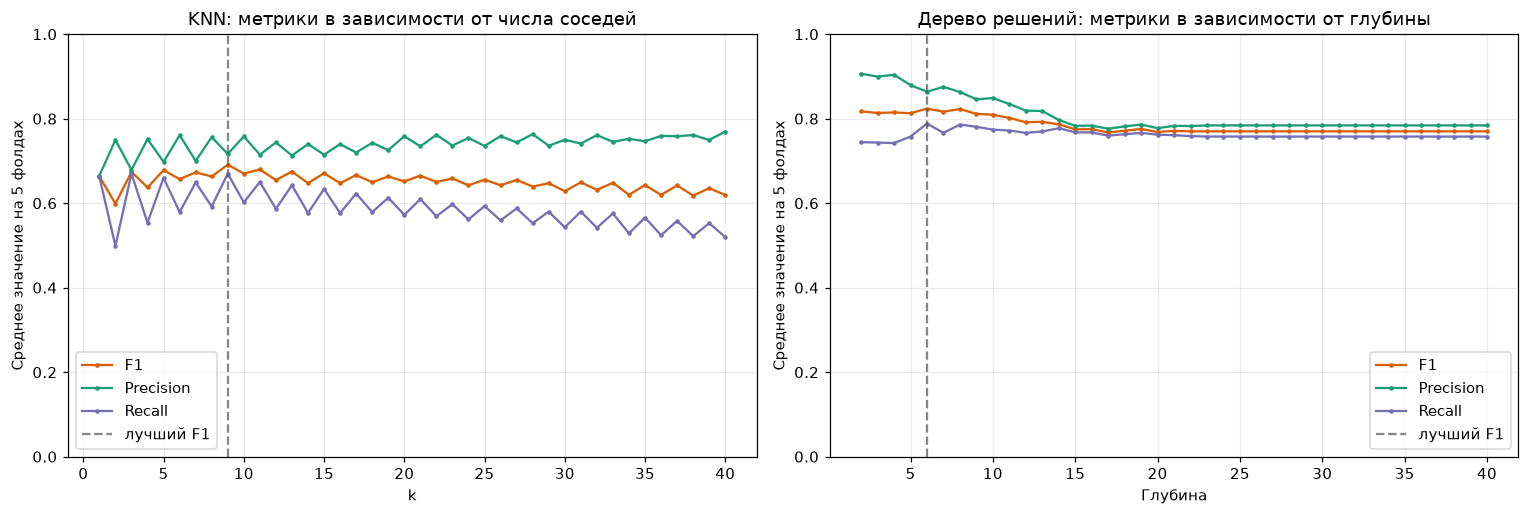

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def metric_values(y_true, y_pred):
    return {
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
    }

def run_parameter_sweeps():
    k_values = list(range(1, 41))
    depth_values = list(range(2, 41))
    metrics_knn = {k: {name: [] for name in ("F1", "Precision", "Recall")} for k in k_values}
    metrics_tree = {d: {name: [] for name in ("F1", "Precision", "Recall")} for d in depth_values}

    for train_idx, valid_idx in cv.split(X_train, y_train):
        X_fold_train, X_fold_valid = X_train.iloc[train_idx], X_train.iloc[valid_idx]
        y_fold_train, y_fold_valid = y_train.iloc[train_idx], y_train.iloc[valid_idx]
        fold_transformer = Pipeline([("feature_builder", FeatureBuilder()), ("preprocessing", preprocessor)])
        X_fold_train_ready = fold_transformer.fit_transform(X_fold_train, y_fold_train)
        X_fold_valid_ready = fold_transformer.transform(X_fold_valid)

        # KNN uses uniform voting by default. The first k neighbors produce the same vote as KNN(k).
        knn_max = KNeighborsClassifier(n_neighbors=max(k_values))
        knn_max.fit(X_fold_train_ready, y_fold_train)
        neighbors = knn_max.kneighbors(X_fold_valid_ready, n_neighbors=max(k_values), return_distance=False)
        neighbor_labels = y_fold_train.to_numpy()[neighbors]
        for k in k_values:
            prediction = (neighbor_labels[:, :k].sum(axis=1) > k / 2).astype("int8")
            scores = metric_values(y_fold_valid, prediction)
            for name, score in scores.items():
                metrics_knn[k][name].append(score)

        for depth in depth_values:
            tree = DecisionTreeClassifier(max_depth=depth, random_state=42)
            tree.fit(X_fold_train_ready, y_fold_train)
            prediction = tree.predict(X_fold_valid_ready)
            scores = metric_values(y_fold_valid, prediction)
            for name, score in scores.items():
                metrics_tree[depth][name].append(score)

    def frame(values, parameter_name):
        rows = []
        for parameter, metric_lists in values.items():
            row = {parameter_name: parameter}
            for name, scores in metric_lists.items():
                row[name] = float(np.mean(scores))
            row["F1_std"] = float(np.std(metric_lists["F1"], ddof=1))
            rows.append(row)
        return pd.DataFrame(rows)

    return frame(metrics_knn, "k"), frame(metrics_tree, "Глубина")

knn_curve, tree_curve = run_parameter_sweeps()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, curve, xcol, title in [
    (axes[0], knn_curve, "k", "KNN: метрики в зависимости от числа соседей"),
    (axes[1], tree_curve, "Глубина", "Дерево решений: метрики в зависимости от глубины"),
]:
    for metric, color in [("F1", "#d95f02"), ("Precision", "#1b9e77"), ("Recall", "#7570b3")]:
        ax.plot(curve[xcol], curve[metric], marker=".", markersize=4, linewidth=1.5, label=metric, color=color)
    best_index = curve["F1"].idxmax()
    ax.axvline(curve.loc[best_index, xcol], color="#555555", linestyle="--", alpha=.7, label="лучший F1")
    ax.set_title(title)
    ax.set_xlabel(xcol)
    ax.set_ylabel("Среднее значение на 5 фолдах")
    ax.set_ylim(0, 1)
    ax.grid(alpha=.25)
    ax.legend()
plt.tight_layout()
plt.show()

best_k = int(knn_curve.loc[knn_curve["F1"].idxmax(), "k"])
best_depth = int(tree_curve.loc[tree_curve["F1"].idxmax(), "Глубина"])
print(f"Оптимальное k по среднему CV F1: {best_k}")
print(f"Оптимальная глубина по среднему CV F1: {best_depth}")

In [7]:
print("Выбранный параметр и контрольные значения для KNN:")
display(knn_curve.loc[knn_curve["k"].isin(sorted(set([1, 5, best_k, 10, 20, 30, 40])))].round(3).set_index("k"))
print("Выбранная глубина и контрольные значения для дерева:")
display(tree_curve.loc[tree_curve["Глубина"].isin(sorted(set([2, 5, 10, 20, 30, 40, best_depth])))].round(3).set_index("Глубина"))

Выбранный параметр и контрольные значения для KNN:
Выбранная глубина и контрольные значения для дерева:


,F1,Precision,Recall,F1_std
k,,,,
1,0.663,0.665,0.662,0.010
5,0.678,0.698,0.660,0.016
9,0.691,0.716,0.670,0.006
10,0.670,0.758,0.602,0.015
20,0.651,0.759,0.572,0.027
30,0.628,0.750,0.543,0.029
40,0.619,0.770,0.520,0.024


,F1,Precision,Recall,F1_std
Глубина,,,,
2,0.817,0.906,0.745,0.023
5,0.813,0.879,0.758,0.022
6,0.824,0.864,0.788,0.014
10,0.809,0.849,0.774,0.021
20,0.769,0.778,0.762,0.034
30,0.770,0.784,0.758,0.036
40,0.770,0.784,0.758,0.036


## 6. Тестовая оценка подобранных моделей

После выбора параметров модель заново обучается на всей обучающей части и один раз оценивается на отложенной тестовой части. Матрицы ошибок показывают число правильно и ошибочно распознанных отмен и продаж.

F1  Precision  Recall
Модель             Выборка                            
KNN (k=9)          Обучающая  0.756      0.788   0.726
                   Тестовая   0.711      0.739   0.684
Дерево (глубина=6) Обучающая  0.843      0.923   0.775
                   Тестовая   0.799      0.879   0.732

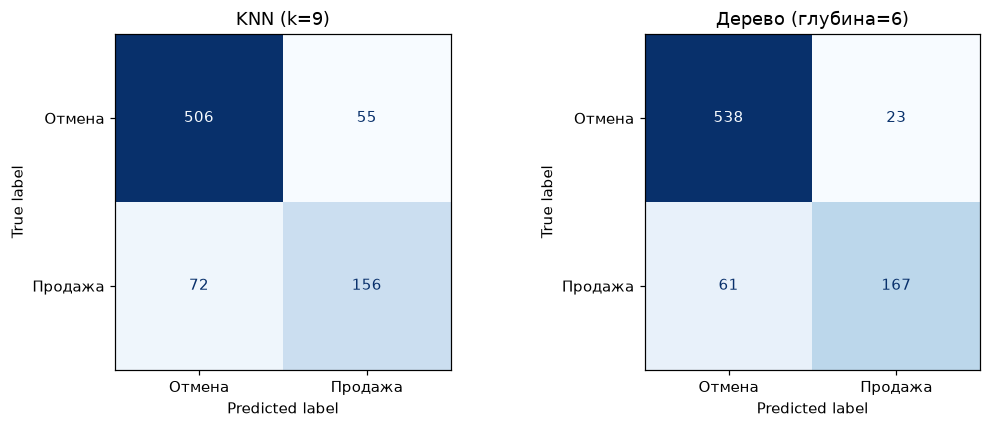

In [8]:
tuned_models = {
    f"KNN (k={best_k})": make_pipeline(KNeighborsClassifier(n_neighbors=best_k)),
    f"Дерево (глубина={best_depth})": make_pipeline(DecisionTreeClassifier(max_depth=best_depth, random_state=42)),
}
tuned_fitted, tuned_rows = {}, []
for label, model in tuned_models.items():
    fitted, rows = evaluate_train_test(model, label)
    tuned_fitted[label] = fitted
    tuned_rows.extend(rows)
tuned_metrics = pd.DataFrame(tuned_rows).set_index(["Модель", "Выборка"]).round(3)
display(tuned_metrics)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (label, fitted) in zip(axes, tuned_fitted.items()):
    ConfusionMatrixDisplay.from_estimator(
        fitted, X_test, y_test, display_labels=["Отмена", "Продажа"],
        cmap="Blues", colorbar=False, ax=ax
    )
    ax.set_title(label)
plt.tight_layout()
plt.show()

In [9]:
best_cv_knn = knn_curve.loc[knn_curve["F1"].idxmax()]
best_cv_tree = tree_curve.loc[tree_curve["F1"].idxmax()]
test_tuned = tuned_metrics.xs("Тестовая", level="Выборка")
best_test_name = test_tuned["F1"].idxmax()
best_test_row = test_tuned.loc[best_test_name]

print(f"Классы сбалансированы: {'да' if abs(y.mean() - 0.5) < 0.05 else 'нет'}. Доля продаж: {y.mean():.1%}; доля отмен: {(1-y.mean()):.1%}.")
print(f"По кросс-валидации лучшее k = {best_k}: F1={best_cv_knn['F1']:.3f}, precision={best_cv_knn['Precision']:.3f}, recall={best_cv_knn['Recall']:.3f}.")
print(f"По кросс-валидации лучшая глубина = {best_depth}: F1={best_cv_tree['F1']:.3f}, precision={best_cv_tree['Precision']:.3f}, recall={best_cv_tree['Recall']:.3f}.")
print(f"Лучшая подобранная модель на тесте по F1: {best_test_name}; F1={best_test_row['F1']:.3f}, precision={best_test_row['Precision']:.3f}, recall={best_test_row['Recall']:.3f}.")
print()
print("Интерпретация: precision — доля реально проданных броней среди предсказанных продаж; recall — доля найденных моделью продаж среди всех продаж. F1 объединяет эти две характеристики.")
print()
print("Ограничение применения: перед прогнозом в момент бронирования нужно проверить, что фактическая стоимость помещения и статус лида в CRM известны на эту дату. Если они фиксируются после исхода, их следует исключить и повторить обучение.")

Классы сбалансированы: нет. Доля продаж: 28.9%; доля отмен: 71.1%.
По кросс-валидации лучшее k = 9: F1=0.691, precision=0.716, recall=0.670.
По кросс-валидации лучшая глубина = 6: F1=0.824, precision=0.864, recall=0.788.
Лучшая подобранная модель на тесте по F1: Дерево (глубина=6); F1=0.799, precision=0.879, recall=0.732.

Интерпретация: precision — доля реально проданных броней среди предсказанных продаж; recall — доля найденных моделью продаж среди всех продаж. F1 объединяет эти две характеристики.

Ограничение применения: перед прогнозом в момент бронирования нужно проверить, что фактическая стоимость помещения и статус лида в CRM известны на эту дату. Если они фиксируются после исхода, их следует исключить и повторить обучение.


## Вывод

Классификация выполнена на данных по жилым помещениям; бинарная цель построена из следующего статуса брони. Сравнение моделей проведено на отложенной выборке, а параметры дополнительного задания выбраны по кросс-валидации только на обучающих данных. Таблицы и графики выше содержат значения метрик, найденные параметры и ошибки классификации.

При выборе для планирования важен баланс двух ошибок: низкий precision означает больше ложных ожиданий по продажам, низкий recall — пропуск большего числа будущих продаж. Поэтому модели сравниваются прежде всего по F1, а окончательный выбор зависит от стоимости этих ошибок для компании.